In [2]:
import pandas as pd
import sklearn
import imblearn
import xgboost

print("pandas:", pd.__version__)
print("sklearn:", sklearn.__version__)
print("imblearn:", imblearn.__version__)
print("xgboost:", xgboost.__version__)

pandas: 3.1.1
sklearn: 1.9.1
imblearn: 0.14.2
xgboost: 3.2.0


In [3]:
data = pd.read_csv("../data/student_mental_health.csv")

In [5]:
data.head(3)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium


In [6]:
print("columns : ", data.columns)

columns :  Index(['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours',
       'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours',
       'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History', 'Mental_Health_Risk'],
      dtype='str')


In [7]:
data.shape

(2000, 17)

In [8]:
data.dtypes

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

In [11]:
display(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

None

In [12]:
data.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [31]:
(data.isnull().sum() * 100/ 2000).T

Student_ID                        0.00
Age                               0.00
Gender                            0.00
Year_of_Study                     0.00
Sleep_Hours                       3.10
Study_Hours_Per_Week              0.00
GPA                               1.90
Social_Media_Hours                2.90
Screen_Time_Hours                 0.00
Physical_Activity                 0.00
Financial_Stress                  4.55
Family_Support                    2.70
Attendance_Rate                   2.35
Part_Time_Job                     0.00
Diet_Quality                      3.45
Previous_Mental_Health_History    0.00
Mental_Health_Risk                0.00
dtype: float64

In [27]:
data.duplicated().sum()

np.int64(0)

In [29]:
data["Mental_Health_Risk"].value_counts()

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
numeric_cols = ["Age", "Sleep_Hours", "Study_Hours_Per_Week", "GPA", "Year_of_Study",
                 "Social_Media_Hours","Screen_Time_Hours","Financial_Stress","Family_Support","Attendance_Rate"]
categorical_cols = ["Gender", "Physical_Activity","Previous_Mental_Health_History","Diet_Quality", "Part_Time_Job"]
target = "Mental_Health_Risk"
risk_order = ["Low", "Medium", "High"]

In [55]:
def plot_distribution(data, col):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(data=data, x=col, kde=True, ax=axes[0])
    axes[0].set_title("Histogram of " + col)

    sns.boxplot(data=data, x=col, ax=axes[1])
    axes[1].set_title("Boxplot of " + col)

    plt.tight_layout()
    plt.show()

    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    print("Column:", col)
    print("Mean:", round(data[col].mean(), 2))
    print("Median:", round(data[col].median(), 2))
    print("Skewness:", round(data[col].skew(), 2))
    print("Min:", data[col].min())
    print("Max:", data[col].max())
    print("Missing:", data[col].isnull().sum())
    print("Missing :", round(data[col].isnull().mean() * 100, 2),"%")
    print("Lower bound:", round(lower, 2))
    print("Upper bound:", round(upper, 2))
    print("Below lower bound:", len(data[data[col] < lower]))
    print("Above upper bound:", len(data[data[col] > upper]))
    print("Rows equal to max:", len(data[data[col] == data[col].max()]))
    print("-" * 40)

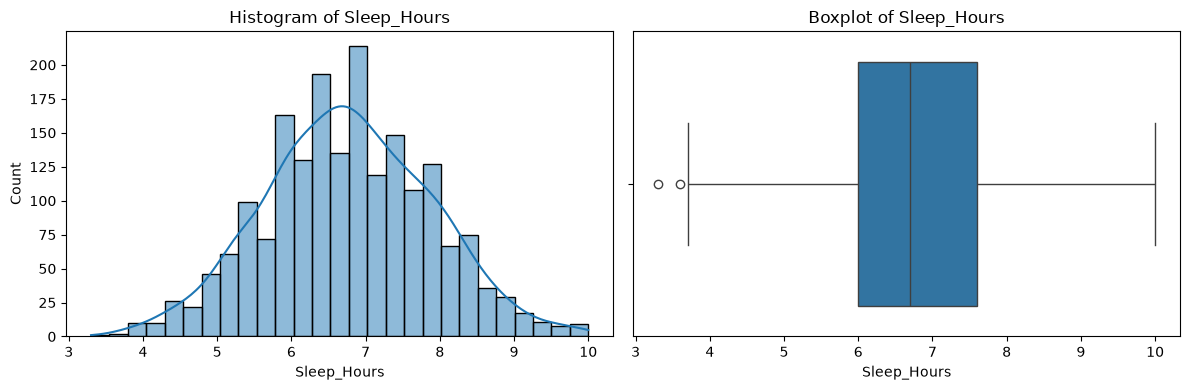

Column: Sleep_Hours
Mean: 6.76
Median: 6.7
Skewness: 0.05
Min: 3.3
Max: 10.0
Missing: 62
Missing : 3.1 %
Lower bound: 3.6
Upper bound: 10.0
Below lower bound: 2
Above upper bound: 0
Rows equal to max: 5
----------------------------------------


In [56]:
plot_distribution(data, "Sleep_Hours")

### Sleep_Hours
- **Shape:** symmetric (mean 6.76 ≈ median 6.7, skewness 0.05). Range 3.3 to 10, realistic.
- **Outliers:** 2 values below the lower bound (3.6), 0 above. Realistic short sleep.
- **Missing:** 62 (3.1%).
- **Decision:** impute with the median. Keep outliers (short sleep is a risk signal). Scale with StandardScaler.

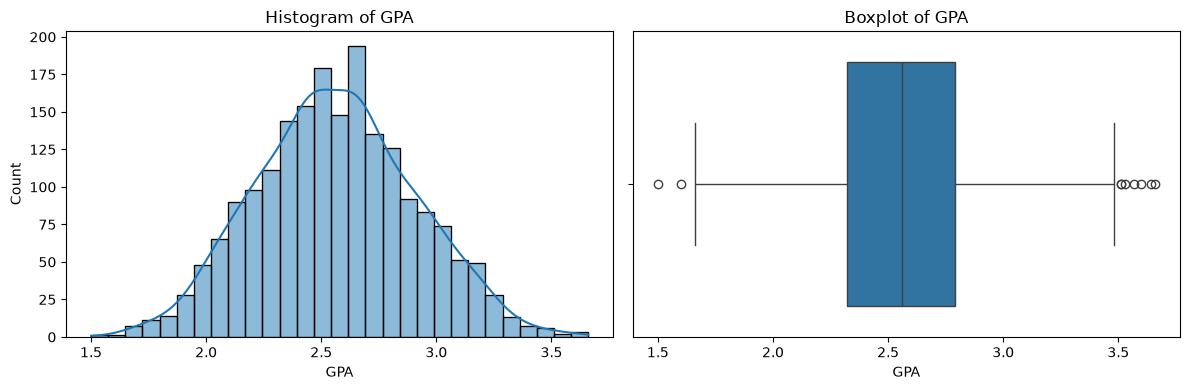

Column: GPA
Mean: 2.56
Median: 2.56
Skewness: 0.09
Min: 1.5
Max: 3.66
Missing: 38
Missing : 1.9 %
Lower bound: 1.61
Upper bound: 3.5
Below lower bound: 2
Above upper bound: 7
Rows equal to max: 1
----------------------------------------


In [57]:
plot_distribution(data, "GPA")

### GPA
- **Shape:** symmetric (mean 2.56 = median 2.56, skewness 0.09). Range 1.5 to 3.66, inside a 0 to 4 scale.
- **Outliers:** 2 below, 7 above (about 0.5%). Realistic grades.
- **Missing:** 38 (1.9%).
- **Decision:** impute with the median. Keep outliers. Scale with StandardScaler.

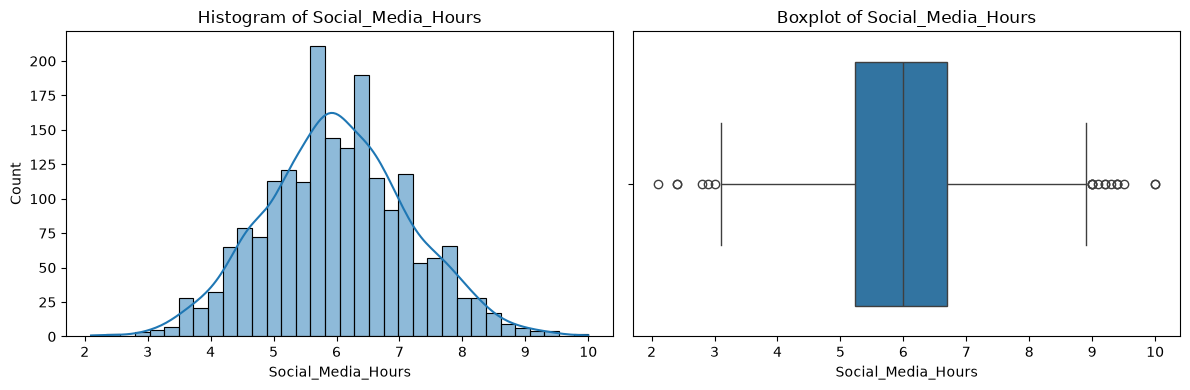

Column: Social_Media_Hours
Mean: 6.01
Median: 6.0
Skewness: 0.09
Min: 2.1
Max: 10.0
Missing: 58
Missing : 2.9 %
Lower bound: 3.01
Upper bound: 8.91
Below lower bound: 6
Above upper bound: 14
Rows equal to max: 2
----------------------------------------


In [58]:
plot_distribution(data, "Social_Media_Hours")

### Social_Media_Hours
- **Shape:** symmetric (mean 6.01 ≈ median 6.0, skewness 0.09).
- **Outliers:** 6 below, 14 above (about 1%). Plausible heavy and light users.
- **Missing:** 58 (2.9%).
- **Problem:** in 37 rows, social media is greater than total screen time (see the logic check below).
- **Decision:** impute with the median. Keep outliers. Scale with StandardScaler.

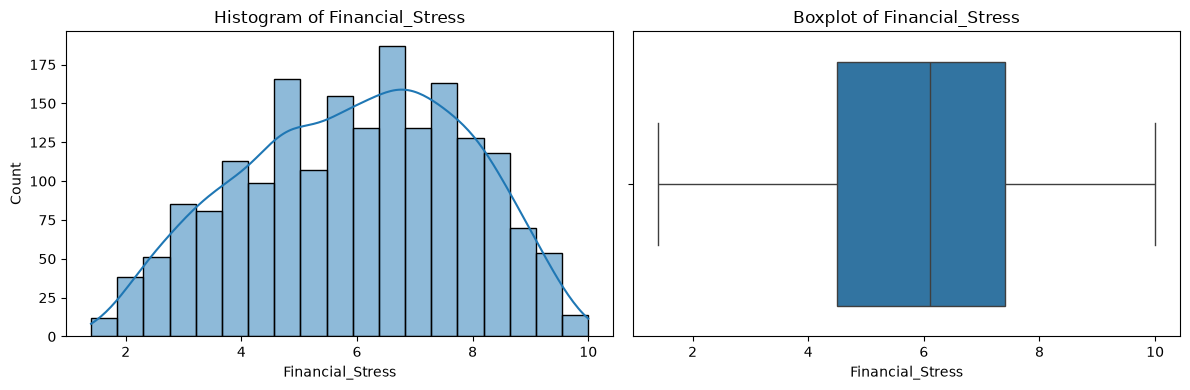

Column: Financial_Stress
Mean: 5.96
Median: 6.1
Skewness: -0.17
Min: 1.4
Max: 10.0
Missing: 91
Missing : 4.55 %
Lower bound: 0.15
Upper bound: 11.75
Below lower bound: 0
Above upper bound: 0
Rows equal to max: 1
----------------------------------------


In [59]:
plot_distribution(data, "Financial_Stress")

### Family_Support
- **Shape:** mildly skewed to the left (mean 6.52 < median 6.7, skewness -0.3). Score from 0 to 10.
- **Outliers:** none by IQR. 9 rows at 9.9 (the max) is normal for a score.
- **Missing:** 54 (2.7%).
- **Decision:** impute with the median (safer than the mean when there is a slight skew). No outlier treatment. Scale with StandardScaler. 

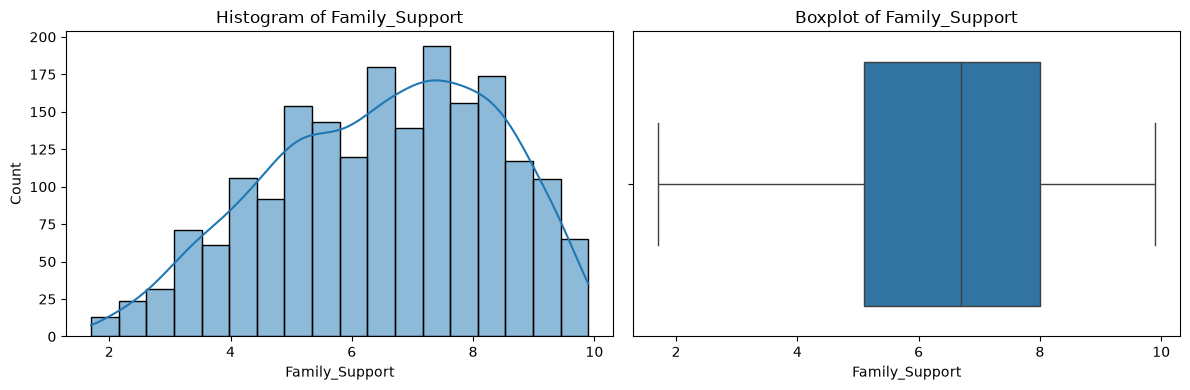

Column: Family_Support
Mean: 6.52
Median: 6.7
Skewness: -0.3
Min: 1.7
Max: 9.9
Missing: 54
Missing : 2.7 %
Lower bound: 0.75
Upper bound: 12.35
Below lower bound: 0
Above upper bound: 0
Rows equal to max: 9
----------------------------------------


In [60]:
plot_distribution(data, "Family_Support")

### Family_Support
- **Shape:** mildly skewed to the left (mean 6.52 < median 6.7, skewness -0.3). Score from 0 to 10.
- **Outliers:** none by IQR. 9 rows at 9.9 (the max) is normal for a score.
- **Missing:** 54 (2.7%).
- **Decision:** impute with the median (safer than the mean when there is a slight skew). No outlier treatment. Scale with StandardScaler.

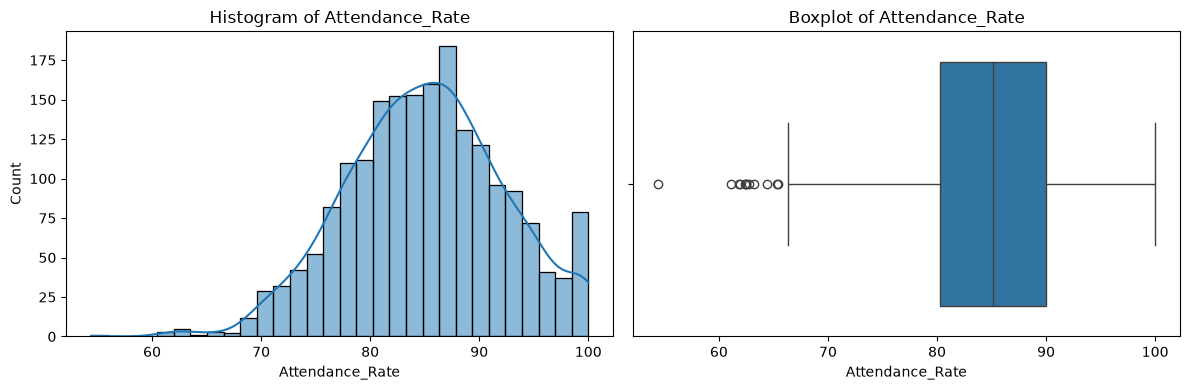

Column: Attendance_Rate
Mean: 85.08
Median: 85.1
Skewness: -0.12
Min: 54.4
Max: 100.0
Missing: 47
Missing : 2.35 %
Lower bound: 65.75
Upper bound: 104.55
Below lower bound: 12
Above upper bound: 0
Rows equal to max: 53
----------------------------------------


In [62]:
plot_distribution(data, "Attendance_Rate")

### Attendance_Rate
- **Shape:** roughly symmetric (mean 85.08 ≈ median 85.1, skewness -0.12). Percentage from 54.4 to 100.
- **Outliers:** 12 below the lower bound (65.75), 0 above. These are students with low attendance, which is a real and meaningful signal.
- **Note:** 53 rows equal 100. This is a natural ceiling for a percentage, not an error.
- **Missing:** 47 (2.35%).
- **Decision:** impute with the median. Keep outliers (low attendance may relate to risk). Scale with StandardScaler.

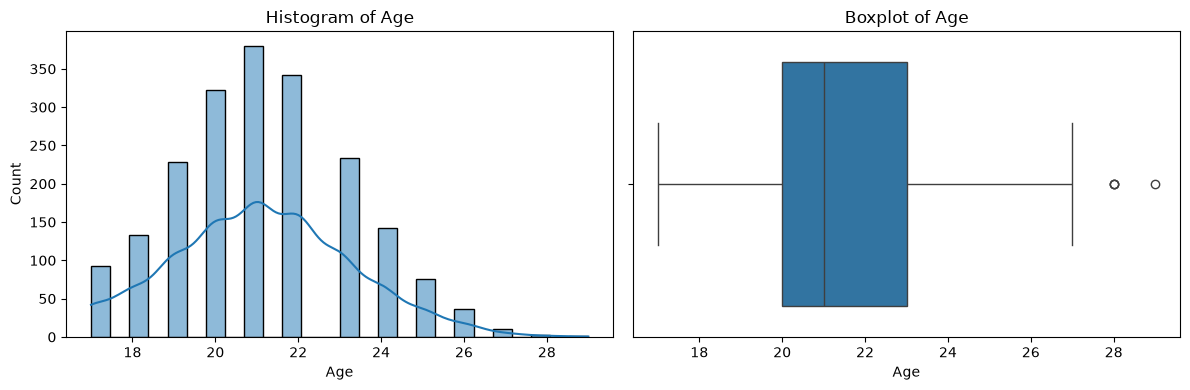

Column: Age
Mean: 21.13
Median: 21.0
Skewness: 0.2
Min: 17
Max: 29
Missing: 0
Missing : 0.0 %
Lower bound: 15.5
Upper bound: 27.5
Below lower bound: 0
Above upper bound: 4
Rows equal to max: 1
----------------------------------------


In [63]:
plot_distribution(data, "Age")

### Age
- **Shape:** almost symmetric (mean 21.13 ≈ median 21, skewness 0.2). Range 17 to 29.
- **Outliers:** 4 above the upper bound (27.5). Older students are realistic.
- **Missing:** 0.
- **Decision:** no imputation. Keep outliers. Scale with StandardScaler.

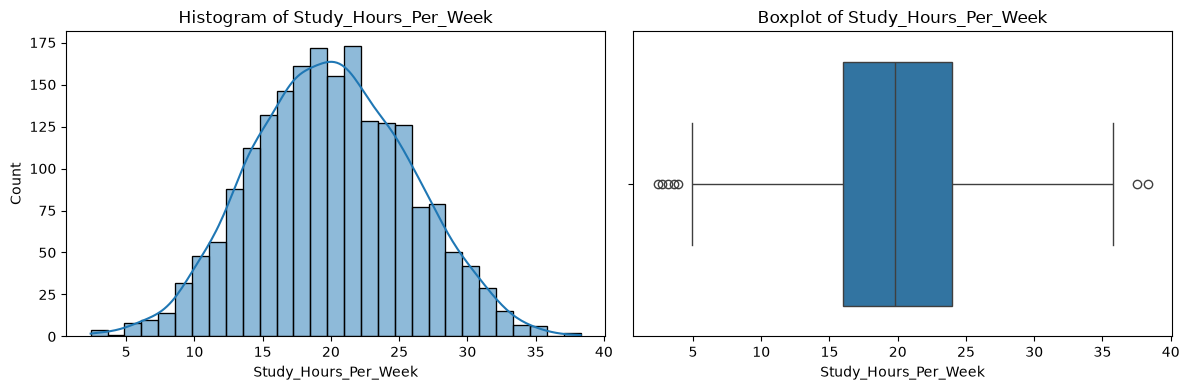

Column: Study_Hours_Per_Week
Mean: 20.0
Median: 19.8
Skewness: 0.04
Min: 2.4
Max: 38.3
Missing: 0
Missing : 0.0 %
Lower bound: 4.0
Upper bound: 36.0
Below lower bound: 5
Above upper bound: 2
Rows equal to max: 1
----------------------------------------


In [64]:
plot_distribution(data, "Study_Hours_Per_Week")

### Study_Hours_Per_Week
- **Shape:** symmetric (mean 20.0 ≈ median 19.8, skewness 0.04). Range 2.4 to 38.3, far below the 168-hour limit.
- **Outliers:** 5 below, 2 above (0.35%). Realistic.
- **Missing:** 0.
- **Decision:** no imputation. Keep outliers. Scale with StandardScaler.

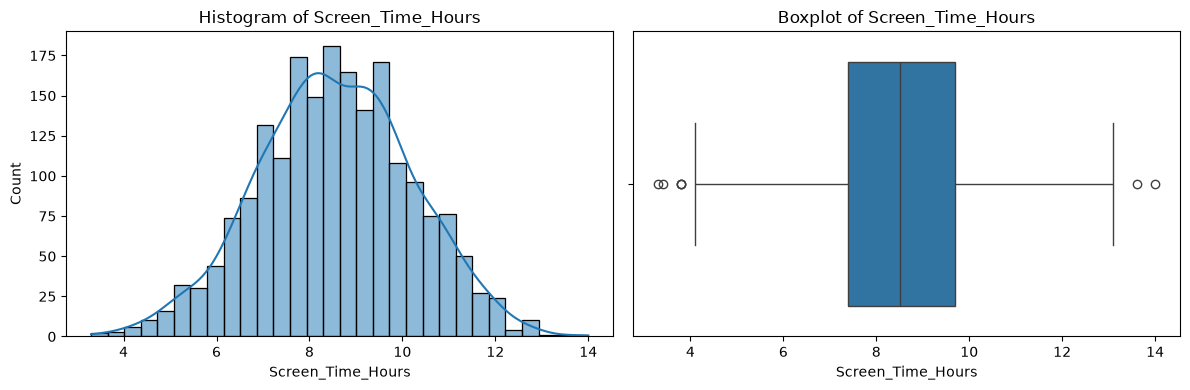

Column: Screen_Time_Hours
Mean: 8.55
Median: 8.5
Skewness: -0.04
Min: 3.3
Max: 14.0
Missing: 0
Missing : 0.0 %
Lower bound: 3.95
Upper bound: 13.15
Below lower bound: 5
Above upper bound: 2
Rows equal to max: 1
----------------------------------------


In [65]:
plot_distribution(data, "Screen_Time_Hours")

### Screen_Time_Hours
- **Shape:** symmetric (mean 8.55 ≈ median 8.5, skewness -0.04). Range 3.3 to 14, below 24 hours, so possible.
- **Outliers:** 5 below, 2 above (0.35%). Realistic.
- **Missing:** 0.
- **Decision:** no imputation. Keep outliers. Scale with StandardScaler. 

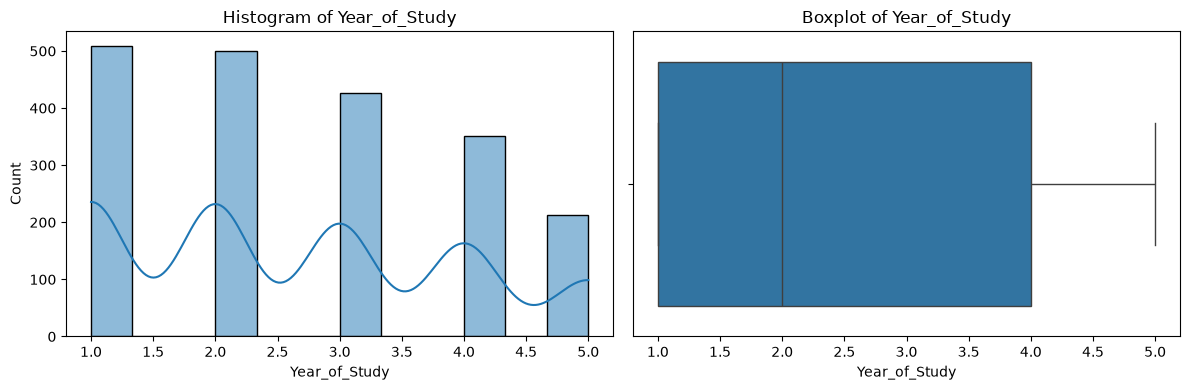

Column: Year_of_Study
Mean: 2.63
Median: 2.0
Skewness: 0.31
Min: 1
Max: 5
Missing: 0
Missing : 0.0 %
Lower bound: -3.5
Upper bound: 8.5
Below lower bound: 0
Above upper bound: 0
Rows equal to max: 213
----------------------------------------


In [66]:
plot_distribution(data, "Year_of_Study")

### Year_of_Study
- **Shape:** discrete values from 1 to 5 (213 rows are year 5). The mean/median/skewness are not very meaningful here.
- **Outliers:** the IQR rule does not apply to a column with 5 possible values. None.
- **Missing:** 0.
- **Decision:** treat as an ordinal variable. Keep it as integers 1 to 5 (the order matters, so no one-hot encoding is needed). Scale with StandardScaler together with the other numeric columns.

In [67]:
print(len(data[data["Social_Media_Hours"] > data["Screen_Time_Hours"]]))

37


### Logic check: Social_Media_Hours vs Screen_Time_Hours
- **Problem:** 37 rows (1.85%) have social media hours greater than total screen time. This is impossible by definition.
- **Cause:** probably noise in a synthetic dataset.
- **Decision:** keep the rows. It is a small share, both values stay within realistic ranges, and removing rows would lose information in other columns. Mention it as a data quality limitation in the README.

In [70]:
display(data[data['Screen_Time_Hours'] >= 14])

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1754,STU1755,22,Female,2,6.0,17.1,2.0,8.0,14.0,Low,9.9,NaN,87.3,Yes,Good,No,High


### Summary of numeric columns
- All 10 numeric columns are symmetric or only slightly skewed.
- 6 columns have missing values, all under 5%. They are imputed with the median, fitted on the training set only (to avoid data leakage).
- All outliers are realistic and few (under 1%), so none are removed.
- All numeric columns are scaled with StandardScaler, inside the pipeline.

In [71]:
print(data['Diet_Quality'].value_counts())

Diet_Quality
Average    860
Poor       587
Good       484
Name: count, dtype: int64


In [72]:
non_binary_risk = data[data['Gender'] == 'Non-binary'].groupby('Mental_Health_Risk').size()
print(non_binary_risk)

Mental_Health_Risk
High      33
Low       39
Medium    25
dtype: int64


In [73]:
for col in categorical_cols :
    print(data[col].value_counts())

Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64
Diet_Quality
Average    860
Poor       587
Good       484
Name: count, dtype: int64
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64


### Gender
- **Values:** Female 971, Male 932, Non-binary 97. No typos, no missing values.
- **Note:** Non-binary is a small group (4.85%). Keep it, do not merge it. Results for this group will be less reliable.
- **Decision:** one-hot encoding (nominal, no order).

### Physical_Activity
- **Values:** Moderate 906, Low 679, High 415. Clean, no missing values.
- **Decision:** ordinal encoding with explicit order Low=0, Moderate=1, High=2.

### Diet_Quality
- **Values:** Average 860, Poor 587, Good 484. Clean spelling.
- **Missing:** 69 (3.45%), not shown by value_counts().
- **Decision:** impute with the most frequent value (Average), fitted on the training set only. Then ordinal encoding with explicit order Poor=0, Average=1, Good=2.

### Previous_Mental_Health_History
- **Values:** No 1408, Yes 592. Binary, no missing values.
- **Decision:** binary encoding (No=0, Yes=1). Moderately imbalanced (30% Yes), which is fine.

### Part_Time_Job
- **Values:** No 1289, Yes 711. Binary, no missing values.
- **Decision:** binary encoding (No=0, Yes=1).

### Summary of categorical columns
- 5 categorical columns, no typos and no rare categories to merge.
- Only Diet_Quality has missing values (3.45%), handled with the most frequent value.
- Encoding: 1 nominal (one-hot), 2 ordinal (explicit order), 2 binary (0/1).
- All fitted on the training set only, inside the pipeline.

In [ ]:
data["Diet_Quality"].isnull().sum()

np.int64(69)

In [76]:
eda = data.copy()
risk_map = {"Low": 0, "Medium": 1, "High": 2}
eda["Risk_Num"] = eda["Mental_Health_Risk"].map(risk_map)

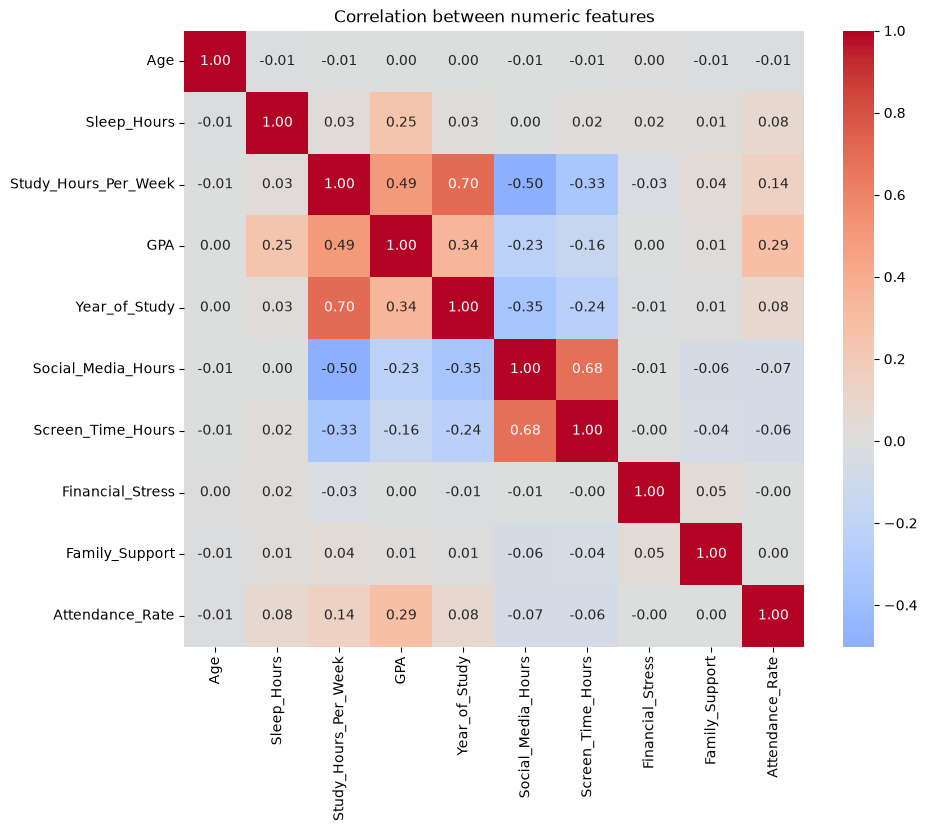

In [77]:
corr = eda[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features")
plt.show()

Sleep_Hours            -0.541857
GPA                    -0.352626
Family_Support         -0.250894
Study_Hours_Per_Week   -0.238793
Year_of_Study          -0.166404
Attendance_Rate        -0.145362
Age                     0.004961
Screen_Time_Hours       0.173972
Social_Media_Hours      0.207601
Financial_Stress        0.313547
Name: Risk_Num, dtype: float64


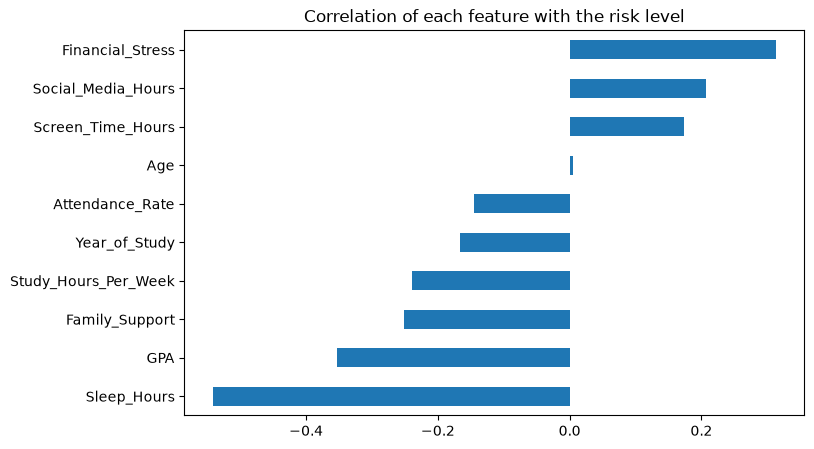

In [ ]:
target_corr = eda[numeric_cols + ["Risk_Num"]].corr()["Risk_Num"]
target_corr = target_corr.drop("Risk_Num")
target_corr = target_corr.sort_values()
print(target_corr)

plt.figure(figsize=(8, 5))
target_corr.plot(kind="barh")
plt.title("Correlation of each feature with the risk level")
plt.show()

In [80]:
display(eda.groupby("Mental_Health_Risk")[numeric_cols].mean().round(2).loc[risk_order])

,Age,Sleep_Hours,Study_Hours_Per_Week,GPA,Year_of_Study,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
Mental_Health_Risk,,,,,,,,,,
Low,21.11,7.52,21.70,2.72,2.90,5.76,8.26,5.24,7.09,86.33
Medium,21.14,6.73,19.98,2.55,2.64,5.92,8.42,5.90,6.53,85.19
High,21.14,6.04,18.36,2.42,2.36,6.35,8.96,6.69,5.96,83.77


### Numeric features vs target
- **Method:** Spearman/Pearson correlation with a temporary numeric target (Low=0, Medium=1, High=2) and the mean of each feature per risk class.
- **Strongest signals:** Sleep_Hours (-0.54), GPA (-0.35), Financial_Stress (+0.31).
- **Moderate signals:** Family_Support (-0.25), Study_Hours_Per_Week (-0.24), Social_Media_Hours (+0.21).
- **Weak signals:** Screen_Time_Hours (+0.17), Year_of_Study (-0.17), Attendance_Rate (-0.15).
- **No linear signal:** Age (0.00).
- **Pattern:** risk is higher for students who sleep less, have lower grades, more financial stress, less family support and more screen time. These are associations, not causes.
- **Decision:** keep all features for now. Age is a candidate for removal after feature importance is checked. Create combined features in Step 2 (see ideas below).


In [82]:
pairs = []
for i in range(len(numeric_cols)):
    for j in range(i + 1, len(numeric_cols)):
        name1 = numeric_cols[i]
        name2 = numeric_cols[j]
        value = corr.loc[name1, name2]
        pairs.append((name1, name2, round(value, 2)))

pairs_sorted = sorted(pairs, key=lambda p: abs(p[2]), reverse=True)

for pair in pairs_sorted[:5]:
    print(pair)

('Study_Hours_Per_Week', 'Year_of_Study', np.float64(0.7))
('Social_Media_Hours', 'Screen_Time_Hours', np.float64(0.68))
('Study_Hours_Per_Week', 'Social_Media_Hours', np.float64(-0.5))
('Study_Hours_Per_Week', 'GPA', np.float64(0.49))
('Year_of_Study', 'Social_Media_Hours', np.float64(-0.35))


In [83]:
for col in categorical_cols:
    table = pd.crosstab(data[col], data[target], normalize="index")
    table = table[risk_order]
    print(col)
    print(table.round(3))
    print("-" * 40)

Gender
Mental_Health_Risk    Low  Medium   High
Gender                                  
Female              0.335   0.319  0.346
Male                0.318   0.349  0.334
Non-binary          0.402   0.258  0.340
----------------------------------------
Physical_Activity
Mental_Health_Risk    Low  Medium   High
Physical_Activity                       
High                0.494   0.304  0.202
Low                 0.228   0.312  0.459
Moderate            0.331   0.355  0.313
----------------------------------------
Previous_Mental_Health_History
Mental_Health_Risk                Low  Medium   High
Previous_Mental_Health_History                      
No                              0.393   0.333  0.274
Yes                             0.181   0.323  0.497
----------------------------------------
Diet_Quality
Mental_Health_Risk    Low  Medium   High
Diet_Quality                            
Average             0.335   0.342  0.323
Good                0.428   0.298  0.275
Poor                0.

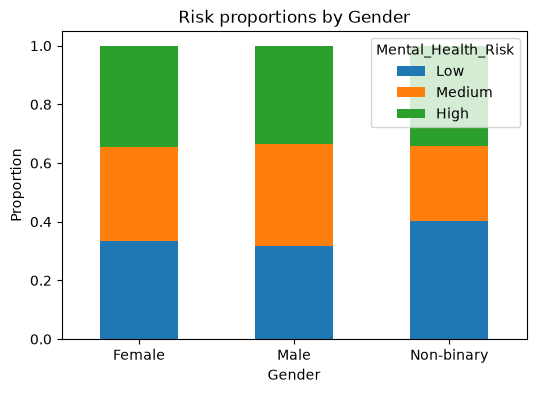

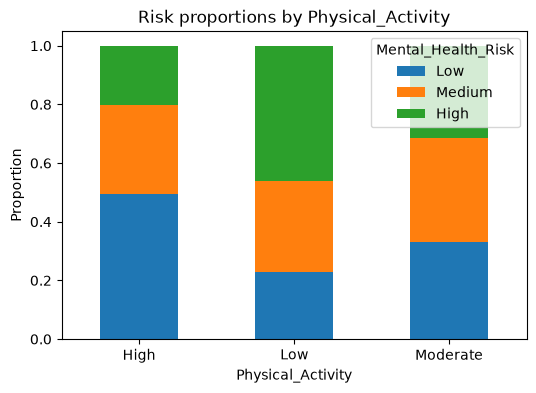

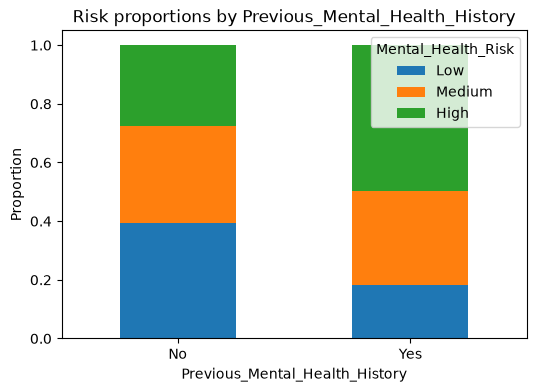

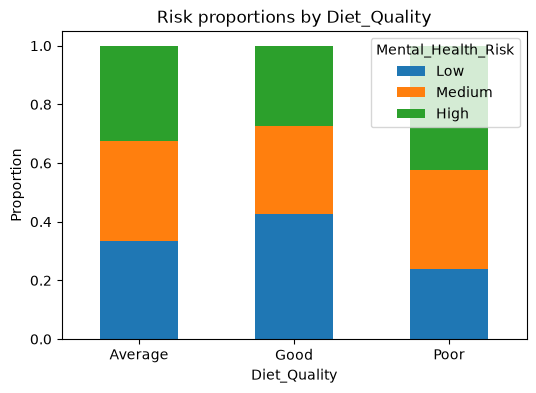

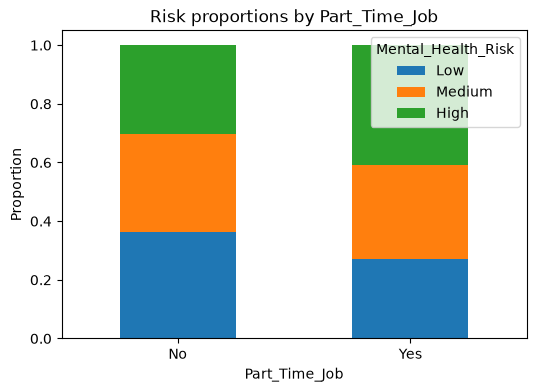

In [84]:
for col in categorical_cols:
    table = pd.crosstab(data[col], data[target], normalize="index")
    table = table[risk_order]
    table.plot(kind="bar", stacked=True, figsize=(6, 4))
    plt.title("Risk proportions by " + col)
    plt.ylabel("Proportion")
    plt.xticks(rotation=0)
    plt.show()

In [85]:
cols_with_missing = ["Sleep_Hours", "GPA", "Social_Media_Hours",
                     "Financial_Stress", "Family_Support",
                     "Attendance_Rate", "Diet_Quality"]

for col in cols_with_missing:
    is_missing = data[col].isnull()
    table = pd.crosstab(is_missing, data[target], normalize="index")
    print(col)
    print(table[risk_order].round(2))
    print("-" * 40)

Sleep_Hours
Mental_Health_Risk   Low  Medium  High
Sleep_Hours                           
False               0.33    0.33  0.34
True                0.21    0.44  0.35
----------------------------------------
GPA
Mental_Health_Risk   Low  Medium  High
GPA                                   
False               0.33    0.33  0.34
True                0.34    0.32  0.34
----------------------------------------
Social_Media_Hours
Mental_Health_Risk   Low  Medium  High
Social_Media_Hours                    
False               0.33    0.33  0.34
True                0.31    0.38  0.31
----------------------------------------
Financial_Stress
Mental_Health_Risk   Low  Medium  High
Financial_Stress                      
False               0.33    0.33  0.35
True                0.37    0.41  0.22
----------------------------------------
Family_Support
Mental_Health_Risk   Low  Medium  High
Family_Support                        
False               0.33    0.33  0.34
True                0.37    

### Relations between numeric features
- No pair is clearly above 0.7. Highest: Study_Hours vs Year_of_Study (0.70) and Social_Media vs Screen_Time (0.68).
- **Decision:** keep all features. Create a ratio feature (social media / screen time) in feature engineering.

### Categorical features vs target
- **Strong:** Previous_Mental_Health_History (Yes: 50% High vs No: 27%) and Physical_Activity (Low: 46% High, High: 20% High).
- **Moderate:** Part_Time_Job (41% vs 30% High) and Diet_Quality.
- **Weak:** Gender. The Non-binary gap is based on only 97 students, so it is probably noise.
- These are associations, not causes.
- **Decision:** keep all categorical features. Gender stays, and the models decide its usefulness.

### Missing values vs target
- GPA, Social_Media_Hours and Diet_Quality: missing rows have the same risk distribution as the others, so the data looks random.
- Sleep_Hours and Financial_Stress: the distribution differs a little, but the groups are small (62 and 91 rows) and several columns were tested, so chance is possible.
- **Decision:** median imputation in the pipeline. Test `add_indicator=True` in Step 3 and keep it only if cross-validation improves.

### EDA summary
- 2000 rows, 17 columns, 0 duplicates. Student_ID is dropped (identifier).
- Target: Low 660, Medium 660, High 680. Balanced, so no SMOTE.
- 7 columns have missing values, all under 5%. Median for numeric, most frequent for Diet_Quality.
- No impossible values, except 37 rows where social media > screen time (kept, noted as a limitation).
- Outliers are few and realistic, so they are kept.
- Strongest signals: Sleep_Hours, Previous_Mental_Health_History, Physical_Activity, GPA, Financial_Stress.
- The dataset looks synthetic (perfectly balanced classes), which is a limitation.